# Детекция спама в текстовых сообщениях

## О проекте

Задача — построить модель, которая автоматически отличает спам-сообщения от обычных. Это одна из ключевых задач для маркетплейсов и сервисов объявлений: фильтрация мошеннических сообщений защищает пользователей и снижает нагрузку на модерацию.

**Данные:** SMS Spam Collection — 5 574 сообщения на английском языке.

**Стек:** Python, pandas, scikit-learn, NLTK, matplotlib, seaborn.

**Этапы работы:**
1. Загрузка и разведочный анализ данных (EDA)
2. Очистка и предобработка текста
3. Векторизация TF-IDF
4. Обучение моделей: Naive Bayes, Logistic Regression
5. Оценка качества и подбор порога классификации

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, f1_score,roc_curve
import joblib
from sklearn.metrics import ConfusionMatrixDisplay

## 1. Загрузка данных

Загружаем датасет из открытого репозитория. Указываем путь к локальной папке со стоп-словами NLTK, чтобы не зависеть от сетевых запросов.

In [44]:
nltk.data.path.append(r'D:\spam-detector\nltk_data')

stop_words = set(stopwords.words('english'))  
print(f"Загружено стоп-слов: {len(stop_words)}")

df = pd.read_csv(
    "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv",
    sep='\t',
    header=None,
    names=['label', 'message']
)

print(df.shape)
print(df['label'].value_counts())
df.head()

Загружено стоп-слов: 198
(5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Разведочный анализ: баланс классов

Проверяем распределение целевой переменной. Классы сильно несбалансированы: обычных сообщений около 87%, спама — около 13%. Это важно учитывать при выборе метрик: accuracy в такой ситуации обманчива, поэтому основное внимание — precision, recall, F1 и ROC-AUC.

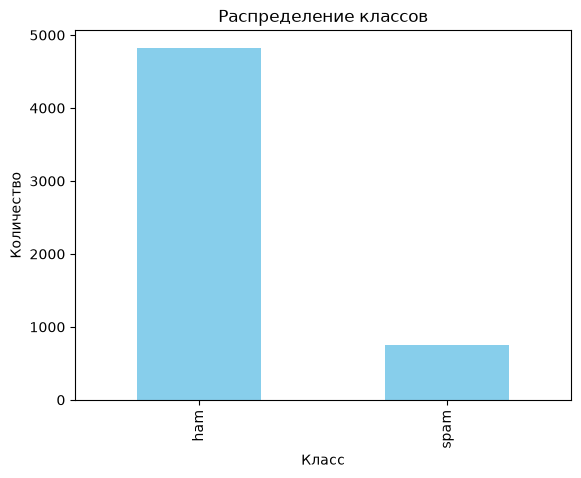

In [45]:
df['label'].value_counts().plot(kind='bar', color='skyblue')
plt.title("Распределение классов")
plt.xlabel("Класс")
plt.ylabel("Количество")
plt.show()

## 3. Разведочный анализ: длина сообщений

Добавляем признак `length` и смотрим его распределение по классам. Спам-сообщения в среднем примерно в два раза длиннее обычных — длина текста может быть полезным сигналом для модели.

In [46]:
df["length"]=df["message"].apply(len)
df.groupby("label")["length"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4825.0,71.482487,58.440652,2.0,33.0,52.0,93.0,910.0
spam,747.0,138.670683,28.873603,13.0,133.0,149.0,157.0,223.0


### Распределение длины по классам

Строим гистограммы отдельно для ham и spam. Распределения заметно различаются: обычные сообщения сконцентрированы в диапазоне 0–100 символов, спам — 100–200.

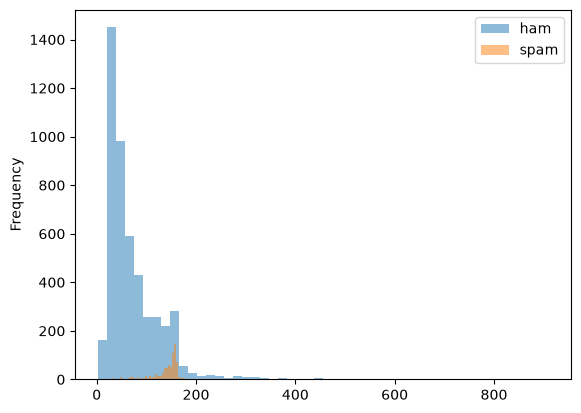

In [47]:
df[df['label']=='ham']["length"].plot(kind="hist", bins=50, alpha=0.5, label='ham')
df[df['label']=='spam']["length"].plot(kind="hist", bins=50, alpha=0.5, label='spam')

plt.legend()
plt.show()

## 4. Предобработка текста

Модели работают с числами, а не с текстом, поэтому сообщения нужно привести к чистому виду:

1. Приведение к нижнему регистру
2. Удаление всего, кроме букв и пробелов (регулярное выражение)
3. Удаление стоп-слов (the, is, a, and и подобных)
4. Обратная склейка слов в строку

In [48]:
def clean_text(strok :str)->str:
    strok=strok.lower()
    strok_new=re.sub(r'[^a-zA-Z\s]', " ", strok)
    words = strok_new.split(" ")
    ar = [w for w in words if w not in stop_words]
    strok = ' '.join(ar)

    return strok

df["clean_message"]=df["message"].apply(clean_text)
df[['message', 'clean_message']].head(10)

df.to_csv("../data/sms_spam_clean.csv", index = False)



## 5. Подготовка данных и векторизация

**Шаги:**
- Формируем признаки `X` (очищенные тексты) и целевую переменную `y` (ham → 0, spam → 1).
- Делим данные на train/test в пропорции 80/20 со стратификацией — это сохраняет исходное соотношение классов в обеих выборках.
- Векторизуем текст методом **TF-IDF**: каждое сообщение превращается в вектор чисел, где вес слова тем выше, чем чаще оно встречается в документе и реже — во всём корпусе.

**Важно:** на train применяем `fit_transform` (изучаем словарь и сразу преобразуем), на test — только `transform` (используем тот же словарь). Иначе возникает утечка данных и метрики становятся нечестными.

In [49]:
X = df["clean_message"]
y=df["label"].map({"ham" : 0, "spam" : 1})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

vectorizer = TfidfVectorizer(max_features=1000, ngram_range=(1,2))

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

## 6. Обучение моделей

**Multinomial Naive Bayes** — вероятностный классификатор, который предполагает независимость слов друг от друга. Классический baseline для задач на текстах: быстрый и хорошо работает на небольших данных.

**Logistic Regression** — линейная модель, которая подбирает вес каждому слову и учитывает их совместный вклад. Даёт интерпретируемые коэффициенты: можно посмотреть, какие слова сильнее всего тянут сообщение в сторону спама.

In [50]:
model_nb = MultinomialNB()
model_lr = LogisticRegression(max_iter=1000)

model_nb.fit(X_train_tfidf, y_train)
pred_nb = model_nb.predict(X_test_tfidf)
prob_nb = model_nb.predict_proba(X_test_tfidf)[:,1]

model_lr.fit(X_train_tfidf, y_train)
pred_lr = model_lr.predict(X_test_tfidf)
prob_lr = model_lr.predict_proba(X_test_tfidf)[:,1]

## 7. Оценка качества моделей

Считаем стандартный набор метрик:

- **Accuracy** — доля правильных ответов (при дисбалансе классов малоинформативна).
- **Precision** — из всех сообщений, которые модель назвала спамом, сколько оказались спамом на самом деле.
- **Recall** — из всех реальных спам-сообщений, сколько модель смогла найти.
- **F1-score** — гармоническое среднее precision и recall, удобно для сравнения моделей.
- **ROC-AUC** — качество ранжирования, не зависит от выбранного порога классификации.

In [51]:
acc_nb = accuracy_score(y_test, pred_nb)
prec_nb=precision_score(y_test, pred_nb)
rec_nb=recall_score(y_test, pred_nb)
f1_nb=f1_score(y_test, pred_nb)
auc_nb=roc_auc_score(y_test, prob_nb)

acc_lr=accuracy_score(y_test, pred_lr)
prec_lr=precision_score(y_test, pred_lr)
rec_lr=recall_score(y_test, pred_lr)
f1_lr=f1_score(y_test, pred_lr)
auc_lr=roc_auc_score(y_test, prob_lr)

metrics = {
    'Метрика': ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
    'Naive Bayes': [acc_nb, prec_nb, rec_nb, f1_nb, auc_nb],
    'Logistic Regression': [acc_lr, prec_lr, rec_lr, f1_lr, auc_lr]
}

metrics_df=pd.DataFrame(metrics)
metrics_df.round(4).head()

,Метрика,Naive Bayes,Logistic Regression
0,Accuracy,0.9767,0.9767
1,Precision,0.9695,1.0000
2,Recall,0.8523,0.8255
3,F1,0.9071,0.9044
4,ROC-AUC,0.9800,0.9834


## 8. Подбор порога классификации

По умолчанию sklearn относит сообщение к спаму, если предсказанная вероятность выше 0.5. Понижая порог, мы ловим больше спама (recall растёт), но увеличиваем число ложных тревог (precision падает). Это классический trade-off, и выбор зависит от бизнес-задачи.

Смотрим, как меняются метрики при разных порогах, чтобы найти оптимальный баланс.

In [52]:
prec_list=[]
rec_list=[]
f1_list=[]

for threshold in [0.5, 0.4, 0.3, 0.2, 0.1]:
    pred_cust = (prob_lr >= threshold).astype(int)
    prec_list.append(precision_score(y_test, pred_cust))
    rec_list.append(recall_score(y_test, pred_cust))
    f1_list.append(f1_score(y_test, pred_cust))
prob_custom=pd.DataFrame({
    'Порог': [0.5, 0.4, 0.3, 0.2, 0.1],
    'Precision': prec_list,
    'Recall': rec_list,
    'F1': f1_list
})

pred_lr_03=(prob_lr>=0.3).astype(int)
acc_lr_03 = accuracy_score(y_test, pred_lr_03)
prec_lr_03 = precision_score(y_test, pred_lr_03)
rec_lr_03=recall_score(y_test, pred_lr_03)
f1_lr_03=f1_score(y_test, pred_lr_03)
auc_lr_03=roc_auc_score(y_test, prob_lr)

In [53]:
X_train_tfidf_dense=X_train_tfidf.toarray()
X_test_tfidf_dense=X_test_tfidf.toarray()

model_gb= HistGradientBoostingClassifier(random_state=42)
model_gb.fit(X_train_tfidf_dense, y_train)

pred_gb=model_gb.predict(X_test_tfidf_dense)
prob_gb=model_gb.predict_proba(X_test_tfidf_dense)[:,1]

acc_gb=accuracy_score(y_test, pred_gb)
prec_gb=precision_score(y_test, pred_gb)
rec_gb=recall_score(y_test, pred_gb)
f1_gb=f1_score(y_test, pred_gb)
auc_gb=roc_auc_score(y_test, prob_gb)


In [54]:
metrics_df["Gradient Boosting"]=[acc_gb, prec_gb, rec_gb, f1_gb, auc_gb]
metrics_df["LR (порог 0.3)"] = [acc_lr_03, prec_lr_03, rec_lr_03, f1_lr_03, auc_lr_03]
metrics_df.head().round(4)

,Метрика,Naive Bayes,Logistic Regression,Gradient Boosting,LR (порог 0.3)
0,Accuracy,0.9767,0.9767,0.9704,0.9812
1,Precision,0.9695,1.0000,0.9265,0.9706
2,Recall,0.8523,0.8255,0.8456,0.8859
3,F1,0.9071,0.9044,0.8842,0.9263
4,ROC-AUC,0.9800,0.9834,0.9727,0.9834


In [55]:
param_grid = {
    'learning_rate' : [0.1],
    'max_iter' : [100],
    'max_depth' : [3, 5]
}

GSV=GridSearchCV(estimator=model_gb, 
                param_grid=param_grid, 
                scoring='roc_auc', 
                cv=3, 
                n_jobs=1, 
                verbose=1)

GSV.fit(X_train_tfidf_dense, y_train)
print("Лучшие параметры:", GSV.best_params_)
print("Лучший ROC-AUC:", GSV.best_score_)
print("Лучшая модель:", GSV.best_estimator_)

pred_gsv=GSV.best_estimator_.predict(X_test_tfidf_dense)
prob_gsv=GSV.best_estimator_.predict_proba(X_test_tfidf_dense)[:,1]

acc_gsv=accuracy_score(y_test, pred_gsv)
prec_gsv=precision_score(y_test, pred_gsv)
rec_gsv=recall_score(y_test, pred_gsv)
f1_gsv=f1_score(y_test, pred_gsv)
auc_gsv=roc_auc_score(y_test, prob_gsv)

metrics_df["GridSearchCV"]=[acc_gsv, prec_gsv, rec_gsv, f1_gsv, auc_gsv]
metrics_df.round(4).head()


Fitting 3 folds for each of 2 candidates, totalling 6 fits
Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 100}
Лучший ROC-AUC: 0.977469676205267
Лучшая модель: HistGradientBoostingClassifier(max_depth=5, random_state=42)


,Метрика,Naive Bayes,Logistic Regression,Gradient Boosting,LR (порог 0.3),GridSearchCV
0,Accuracy,0.9767,0.9767,0.9704,0.9812,0.9722
1,Precision,0.9695,1.0000,0.9265,0.9706,0.9683
2,Recall,0.8523,0.8255,0.8456,0.8859,0.8188
3,F1,0.9071,0.9044,0.8842,0.9263,0.8873
4,ROC-AUC,0.9800,0.9834,0.9727,0.9834,0.9795


In [56]:
print("Размер df:", df.shape)
print("Баланс классов:", df['label'].value_counts().to_dict())
print("Размер X_train_tfidf:", X_train_tfidf.shape)
print("Размер X_test_tfidf:", X_test_tfidf.shape)
print("Пример clean_message:", df['clean_message'].iloc[0])
print("Пример y:", y.head().tolist())

Размер df: (5572, 4)
Баланс классов: {'ham': 4825, 'spam': 747}
Размер X_train_tfidf: (4457, 1000)
Размер X_test_tfidf: (1115, 1000)
Пример clean_message: go jurong point  crazy   available bugis n great world la e buffet    cine got amore wat   
Пример y: [0, 0, 1, 0, 0]


In [57]:
print("max_features:", vectorizer.max_features)
print("ngram_range:", vectorizer.ngram_range)
print("тип X_train:", type(X_train))
print("первые 3 текста X_train:")
print(X_train.head(3).tolist())
print("первые 20 признаков:")
print(vectorizer.get_feature_names_out()[:20])

max_features: 1000
ngram_range: (1, 2)
тип X_train: <class 'pandas.Series'>
первые 3 текста X_train:
[' guys close ', 'please come imin town dontmatter urgoin outl r reallyneed  docd please dontplease dontignore mycalls u thecd isv important tome    moro', 'ok k  sry knw   siva  tats askd  ']
первые 20 признаков:
['able' 'abt' 'ac' 'account' 'account statement' 'across' 'across sea'
 'actually' 'address' 'aft' 'afternoon' 'age' 'ago' 'ah' 'aight' 'almost'
 'alone' 'already' 'alright' 'also']


In [61]:
joblib.dump(model_lr, '../models/lr_model.pkl')
joblib.dump(vectorizer, '../models/tfidf_vectorizer.pkl')
loaded_model=joblib.load('../models/lr_model.pkl')

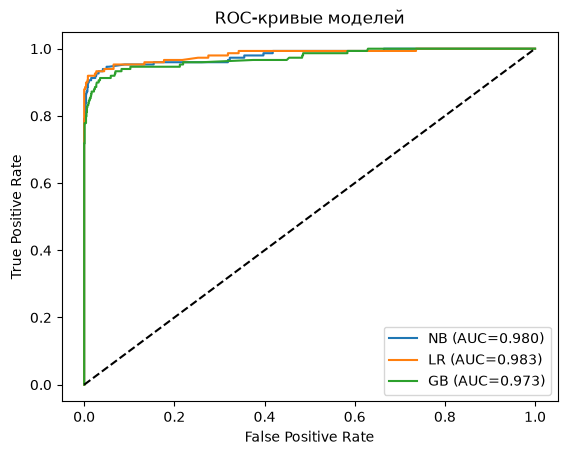

In [65]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, prob_lr)
fpr_nb, tpr_nb, _ = roc_curve(y_test, prob_nb)
fpr_gb, tpr_gb, _ = roc_curve(y_test, prob_gb)

plt.plot(fpr_nb, tpr_nb, label=f'NB (AUC={auc_nb:.3f})')
plt.plot(fpr_lr, tpr_lr, label=f'LR (AUC={auc_lr:.3f})')
plt.plot(fpr_gb, tpr_gb, label=f'GB (AUC={auc_gb:.3f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей')
plt.legend()
plt.savefig('../reports/figures/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

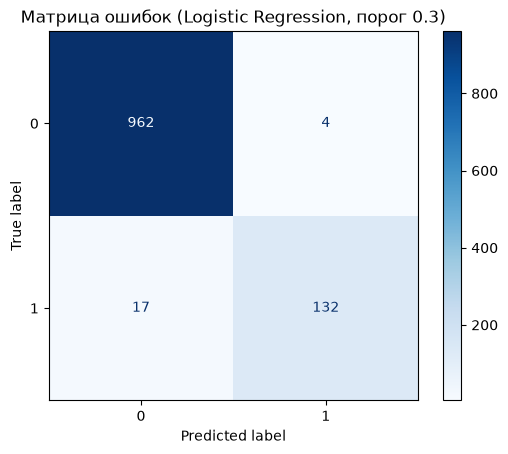

In [67]:
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr_03, cmap='Blues')
plt.title('Матрица ошибок (Logistic Regression, порог 0.3)')

plt.savefig('../reports/figures/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()